# A sugar tax is not one number

Cities adopt a sugar tax at different times. The average drop in brand sales answers how large the tax effect was. It does not answer whether high-sugar brands were hit harder than low-sugar brands. That incremental impact is a contrast of two staggered difference-in-differences, not a new untreated-outcome model.

The {doc}`../knowledgebase/staggered-difference-in-differences-in-differences` page says what the contrast is, when an event time is compared, and why subtracting published intervals is not an uncertainty statement. This notebook fits the two brand groups and prints the contrast in simulated sales units.

High and low sugar are defined before the tax. Brands do not sit in both groups. Both groups share the same adoption times and the same event window. The fit below is ordinary least squares, so each group returns a point estimate and no posterior draws. A Bayesian fit would subtract `att_event_time_draws` the same way; that subtraction is shown afterwards with labeled illustration numbers, not with this fit.


In [1]:
#| code-fold: true
import warnings

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

import causalpy as cp
from causalpy.data.simulate_data import generate_staggered_did_data

warnings.filterwarnings(
    "ignore",
    message="LinearRegression had fit_intercept",
)

## Two brand groups, one adoption calendar

Each brand is treated when its city adopts, at time 4 or never. The panel unit is the brand, not the city. High-sugar sales are generated with a treatment effect of 4. Low-sugar sales are generated with a treatment effect of 1. The incremental impact to recover is about 3 sales units. Unit identifiers do not overlap, so a brand is in only one sugar profile.


In [2]:
def brand_panel(effect, sugar, unit_offset, seed):
    frame = generate_staggered_did_data(
        n_units=16,
        n_time_periods=10,
        treatment_cohorts={4: 8},
        treatment_effects={0: effect},
        sigma=0.05,
        seed=seed,
    )
    frame["unit"] = frame["unit"] + unit_offset
    frame["sugar"] = sugar
    return frame


sales = pd.concat(
    [
        brand_panel(4.0, "high", 0, 11),
        brand_panel(1.0, "low", 100, 12),
    ],
    ignore_index=True,
)
sales.groupby("sugar")["treatment_time"].agg(lambda s: sorted(set(s))).to_frame(
    "adoption times"
)

,adoption times
sugar,
high,"[4.0, inf]"
low,"[4.0, inf]"


The adoption times match. Never-treated brands are marked with infinity. The untreated-outcome formula is the same imputation specification used for staggered DiD, with unit and time fixed effects. Sugar is not in the formula: inside a group it does not vary.


In [3]:
result = cp.StaggeredDifferenceInDifferencesInDifferences(
    sales,
    formula="y ~ 1 + C(unit) + C(time)",
    unit_variable_name="unit",
    time_variable_name="time",
    level_variable_name="sugar",
    treatment_time_variable_name="treatment_time",
    model=LinearRegression(),
    reference_level="low",
).fit()

## The contrast is the difference of the two tables

Each group keeps its own event-time ATT. The contrast table keeps an event time only when both groups identify it, and the sign is high minus low because low is the reference.


In [4]:
levels = result.level_att_event_time()
contrast = result.contrast_att_event_time()
shared = 0
high_att = levels.loc[
    (levels["level"] == "high") & (levels["event_time"] == shared), "att"
].iloc[0]
low_att = levels.loc[
    (levels["level"] == "low") & (levels["event_time"] == shared), "att"
].iloc[0]
print(f"Event time {shared}: {high_att:.2f} - {low_att:.2f} = {high_att - low_att:.2f}")
contrast.loc[:, ["level_a", "level_b", "event_time", "att"]]

Event time 0: 3.96 - 0.94 = 3.03


,level_a,level_b,event_time,att
0,high,low,-4,-0.003253
1,high,low,-3,-0.007494
2,high,low,-2,-0.001901
3,high,low,-1,0.012648
4,high,low,0,3.028257
5,high,low,1,3.004416
6,high,low,2,2.937315
7,high,low,3,2.981343
8,high,low,4,2.996710
9,high,low,5,2.959001


The printed line is event time 0, the first treated period. It sits near the planted gap of 3 sales units. The pre-treatment rows in the table stay near zero: the groups were not already pulling apart before the tax.


## The plots are the tables

The first panel is each sugar profile's event-time ATT. The second is the high-minus-low curve. The third is the overall post-treatment contrast, one dot for the pair. This OLS fit has no interval bars. The points are the table values, not a second calculation.


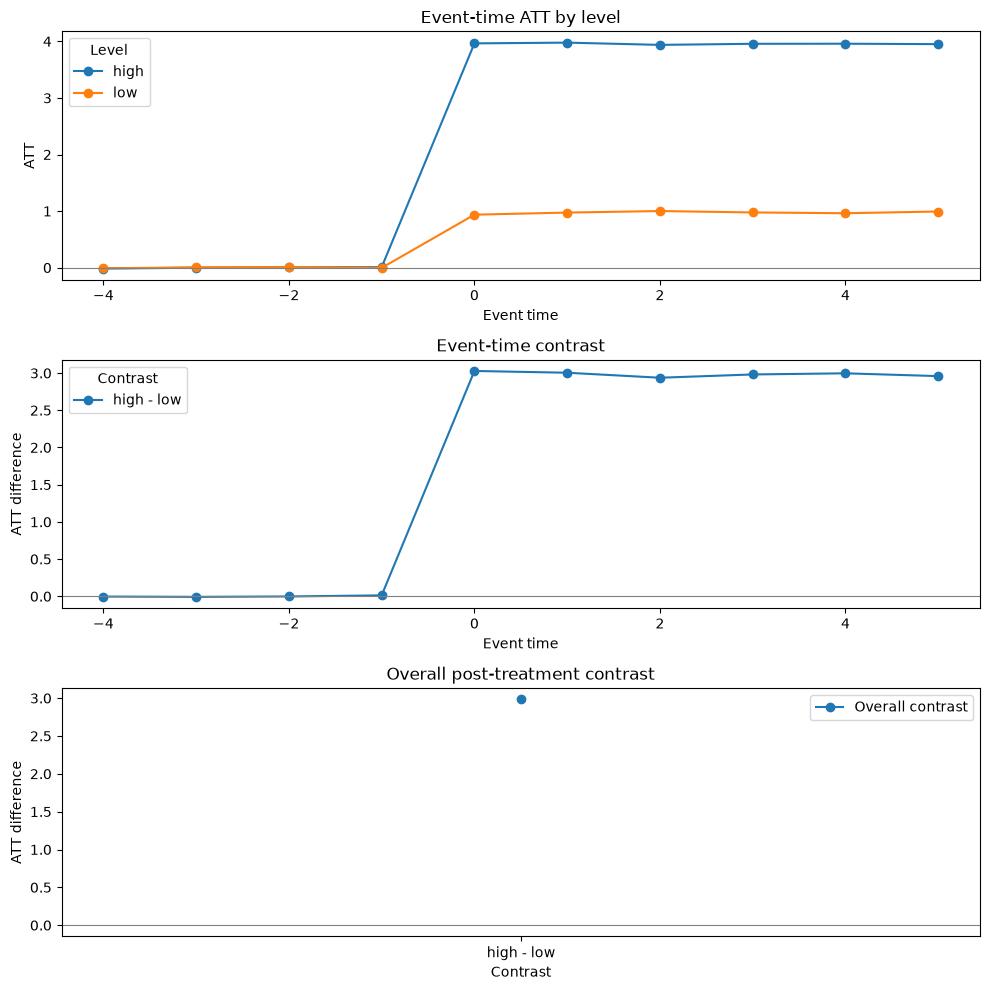

In [5]:
#| code-fold: true
fig, axes = result.plot()

## An interval is a column of differences

These three pairs are an illustration. They are not stored draws from the OLS fit above, which has none. `contrast_draws` subtracts within each pair. A Bayesian fit's `att_event_time_draws` are subtracted by the same function.


In [6]:
illustration = cp.StaggeredDifferenceInDifferencesInDifferences.contrast_draws(
    np.array([7.0, 9.0, 11.0]),
    np.array([5.0, 3.0, 1.0]),
)
illustration

array([ 2.,  6., 10.])

The differences are 2, 6, and 10. That spread is the uncertainty of the contrast. The two illustration columns have the same standard error, so subtracting standard errors would have said the contrast was known exactly.

## What the sales gap does not decide

The overall high-minus-low estimate is an incremental impact in sales units: how much larger the tax effect was for high-sugar brands than for low-sugar brands. It does not say the tax was the right tax. It does not remove a shock that hit both profiles unless, without the tax, the treated-minus-untreated sales trend would have matched across sugar profiles. That remains an assumption.

The imputation inside each group is the estimator in {cite:t}`borusyak2024revisiting`. The contrast does not replace it.

:::{bibliography}
:filter: docname in docnames
:::
